<a href="https://colab.research.google.com/github/mardorsan/sds510/blob/main/EssentialsMod3Quiz.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Module 3 Quiz Essentials**

In this section, I just load in the dataset and import all the packages I will need. Additionally, I would load each dataset indiviudally and then go and run the loading code again in order to reset the value of 'path' to load the csv into the program.

I also rename some of the columns to have an easier time later.

In [8]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mariapushkareva/phoenix-crime-data")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'phoenix-crime-data' dataset.
Path to dataset files: /kaggle/input/phoenix-crime-data


In [14]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("selfishgene/historical-hourly-weather-data")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'historical-hourly-weather-data' dataset.
Path to dataset files: /kaggle/input/historical-hourly-weather-data


In [108]:
import pandas as pd
import os
import re
import csv
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

In [54]:
#n = pd.read_csv(path)
os.listdir(path)
#n.drop(columns='Unnamed: 0',inplace=True)
#n

['weather_description.csv',
 'pressure.csv',
 'wind_speed.csv',
 'city_attributes.csv',
 'temperature.csv',
 'wind_direction.csv',
 'humidity.csv']

In [56]:
weather_desc = pd.read_csv(
    os.path.join(path, "weather_description.csv"),
    engine = "python",
    on_bad_lines = "skip"
)

weather_desc.head()

,datetime,Vancouver,Portland,San Francisco,Seattle,Los Angeles,San Diego,Las Vegas,Phoenix,Albuquerque,...,Philadelphia,New York,Montreal,Boston,Beersheba,Tel Aviv District,Eilat,Haifa,Nahariyya,Jerusalem
0,2012-10-01 12:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,haze,NaN,NaN,NaN
1,2012-10-01 13:00:00,mist,scattered clouds,light rain,sky is clear,mist,sky is clear,sky is clear,sky is clear,sky is clear,...,broken clouds,few clouds,overcast clouds,sky is clear,sky is clear,sky is clear,haze,sky is clear,sky is clear,sky is clear
2,2012-10-01 14:00:00,broken clouds,scattered clouds,sky is clear,sky is clear,sky is clear,sky is clear,sky is clear,sky is clear,sky is clear,...,broken clouds,few clouds,sky is clear,few clouds,sky is clear,sky is clear,broken clouds,overcast clouds,sky is clear,overcast clouds
3,2012-10-01 15:00:00,broken clouds,scattered clouds,sky is clear,sky is clear,sky is clear,sky is clear,sky is clear,sky is clear,sky is clear,...,broken clouds,few clouds,sky is clear,few clouds,overcast clouds,sky is clear,broken clouds,overcast clouds,overcast clouds,overcast clouds
4,2012-10-01 16:00:00,broken clouds,scattered clouds,sky is clear,sky is clear,sky is clear,sky is clear,sky is clear,sky is clear,sky is clear,...,broken clouds,few clouds,sky is clear,few clouds,overcast clouds,sky is clear,broken clouds,overcast clouds,overcast clouds,overcast clouds


In [57]:
humidity = pd.read_csv(
    os.path.join(path, "humidity.csv"),
    engine = "python",
    on_bad_lines = "skip"
)

humidity.head()

,datetime,Vancouver,Portland,San Francisco,Seattle,Los Angeles,San Diego,Las Vegas,Phoenix,Albuquerque,...,Philadelphia,New York,Montreal,Boston,Beersheba,Tel Aviv District,Eilat,Haifa,Nahariyya,Jerusalem
0,2012-10-01 12:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,25.0,NaN,NaN,NaN
1,2012-10-01 13:00:00,76.0,81.0,88.0,81.0,88.0,82.0,22.0,23.0,50.0,...,71.0,58.0,93.0,68.0,50.0,63.0,22.0,51.0,51.0,50.0
2,2012-10-01 14:00:00,76.0,80.0,87.0,80.0,88.0,81.0,21.0,23.0,49.0,...,70.0,57.0,91.0,68.0,51.0,62.0,22.0,51.0,51.0,50.0
3,2012-10-01 15:00:00,76.0,80.0,86.0,80.0,88.0,81.0,21.0,23.0,49.0,...,70.0,57.0,87.0,68.0,51.0,62.0,22.0,51.0,51.0,50.0
4,2012-10-01 16:00:00,77.0,80.0,85.0,79.0,88.0,81.0,21.0,23.0,49.0,...,69.0,57.0,84.0,68.0,52.0,62.0,22.0,51.0,51.0,50.0


In [20]:
crime = pd.read_csv(
    os.path.join(path, "crimestat (1).csv"),
    engine = "python",
    on_bad_lines = "skip"
)

crime.head()

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/input/historical-hourly-weather-data/crimestat (1).csv'

In [23]:
crime.rename(columns={'INC NUMBER': 'INC_NUMBER',
                      'UCR CRIME CATEGORY': 'UCR_CRIME_CATEGORY',
                      'OCCURRED ON': 'OCCURRED_ON',
                      'OCCURRED TO': 'OCCURRED_TO',
                      '100 BLOCK ADDR': 'hundred_BLOCK_ADDR',
                      'PREMISE TYPE': 'PREMISE_TYPE'}, inplace=True)

crime.head()

,INC_NUMBER,OCCURRED_ON,OCCURRED_TO,UCR_CRIME_CATEGORY,hundred_BLOCK_ADDR,ZIP,PREMISE_TYPE
0,201600000052855,11/01/2015 00:00,01/09/2016 00:00,MOTOR VEHICLE THEFT,N 43RD AVE & W CACTUS RD,85029.0,SINGLE FAMILY HOUSE
1,201600000594484,11/01/2015 00:00,NaN,RAPE,13XX E ALMERIA RD,85006.0,SINGLE FAMILY HOUSE
2,201500002102327,11/01/2015 00:00,11/01/2015 09:00,LARCENY-THEFT,51XX N 15TH ST,85014.0,APARTMENT
3,201500002101405,11/01/2015 00:00,11/01/2015 05:00,MOTOR VEHICLE THEFT,102XX W MEDLOCK AVE,85307.0,SINGLE FAMILY HOUSE
4,201500002102668,11/01/2015 00:00,11/01/2015 11:50,MOTOR VEHICLE THEFT,69XX W WOOD ST,85043.0,SINGLE FAMILY HOUSE


In [67]:
humidityP = humidity[["datetime","Phoenix"]]
weather_descP = weather_desc[["datetime","Phoenix"]]

In [59]:
humidityP.head()

,datetime,Phoenix
0,2012-10-01 12:00:00,NaN
1,2012-10-01 13:00:00,23.0
2,2012-10-01 14:00:00,23.0
3,2012-10-01 15:00:00,23.0
4,2012-10-01 16:00:00,23.0



---


## Finding How daily Humidity affects the number of crimes per day

---


In [68]:
weather_descP.rename(columns={'Phoenix': 'weather_descs'}, inplace=True)


/tmp/ipykernel_636/2740639292.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_descP.rename(columns={'Phoenix': 'weather_descs'}, inplace=True)


In [69]:
crimeDatesjust = crime.groupby("OCCURRED_ON")
crimeDatesjust.OCCURRED_ON.value_counts()

,count
OCCURRED_ON,
2015-11-01 00:00:00,10
2015-11-01 00:01:00,14
2015-11-01 00:05:00,1
2015-11-01 00:30:00,1
2015-11-01 01:00:00,2
...,...
2017-11-17 04:00:00,1
2017-11-17 04:15:00,1
2017-11-17 05:00:00,1


In [70]:
crime["OCCURRED_ON"] = pd.to_datetime(crime["OCCURRED_ON"], format = '%m/%d/%Y %H:%M')
humidityP["datetime"] = pd.to_datetime(humidityP["datetime"])
weather_descP["datetime"] = pd.to_datetime(weather_descP["datetime"])



/tmp/ipykernel_636/1830222137.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  humidityP["datetime"] = pd.to_datetime(humidityP["datetime"])
/tmp/ipykernel_636/1830222137.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_descP["datetime"] = pd.to_datetime(weather_descP["datetime"])


In [82]:
crimeWeather = crime.merge(humidityP[["datetime", "Phoenix"]], left_on = "OCCURRED_ON", right_on = "datetime", how = "left")

In [83]:
crimeWeather = crimeWeather.merge(weather_descP[["datetime", "weather_descs"]], left_on = "OCCURRED_ON", right_on = "datetime", how = "left")

In [85]:
crimeWeather.head()

,INC_NUMBER,OCCURRED_ON,OCCURRED_TO,UCR_CRIME_CATEGORY,hundred_BLOCK_ADDR,ZIP,PREMISE_TYPE,year,datetime_x,Phoenix,datetime_y,weather_descs
0,201600000052855,2015-11-01,01/09/2016 00:00,MOTOR VEHICLE THEFT,N 43RD AVE & W CACTUS RD,85029.0,SINGLE FAMILY HOUSE,2015.0,2015-11-01,28.0,2015-11-01,sky is clear
1,201600000594484,2015-11-01,NaN,RAPE,13XX E ALMERIA RD,85006.0,SINGLE FAMILY HOUSE,2015.0,2015-11-01,28.0,2015-11-01,sky is clear
2,201500002102327,2015-11-01,11/01/2015 09:00,LARCENY-THEFT,51XX N 15TH ST,85014.0,APARTMENT,2015.0,2015-11-01,28.0,2015-11-01,sky is clear
3,201500002101405,2015-11-01,11/01/2015 05:00,MOTOR VEHICLE THEFT,102XX W MEDLOCK AVE,85307.0,SINGLE FAMILY HOUSE,2015.0,2015-11-01,28.0,2015-11-01,sky is clear
4,201500002102668,2015-11-01,11/01/2015 11:50,MOTOR VEHICLE THEFT,69XX W WOOD ST,85043.0,SINGLE FAMILY HOUSE,2015.0,2015-11-01,28.0,2015-11-01,sky is clear


In [ ]:
print(crime.columns.tolist())

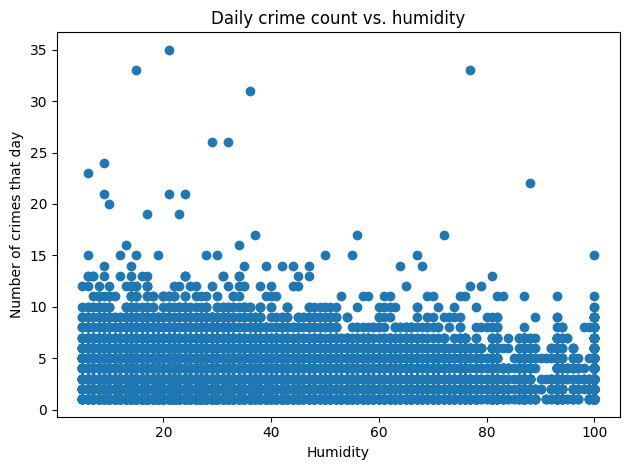

In [87]:
daily = (crimeWeather.dropna(subset=["OCCURRED_ON", "Phoenix"]).groupby("OCCURRED_ON").agg(crime_count=("INC_NUMBER", "nunique"), humidity=("Phoenix", "mean")).reset_index())

plt.scatter("humidity", "crime_count", data = daily)
plt.xlabel("Humidity")
plt.ylabel("Number of crimes that day")
plt.title("Daily crime count vs. humidity")
plt.tight_layout()
plt.show()



---


## Making a bar graph showing amount of crime on each weather description

---



In [96]:
weather_descG = crimeWeather.groupby("weather_descs")
weather_descG.weather_descs.value_counts()
weather_descG.head()

,INC_NUMBER,OCCURRED_ON,OCCURRED_TO,UCR_CRIME_CATEGORY,hundred_BLOCK_ADDR,ZIP,PREMISE_TYPE,year,datetime_x,Phoenix,datetime_y,weather_descs
0,201600000052855,2015-11-01 00:00:00,01/09/2016 00:00,MOTOR VEHICLE THEFT,N 43RD AVE & W CACTUS RD,85029.0,SINGLE FAMILY HOUSE,2015.0,2015-11-01 00:00:00,28.0,2015-11-01 00:00:00,sky is clear
1,201600000594484,2015-11-01 00:00:00,NaN,RAPE,13XX E ALMERIA RD,85006.0,SINGLE FAMILY HOUSE,2015.0,2015-11-01 00:00:00,28.0,2015-11-01 00:00:00,sky is clear
2,201500002102327,2015-11-01 00:00:00,11/01/2015 09:00,LARCENY-THEFT,51XX N 15TH ST,85014.0,APARTMENT,2015.0,2015-11-01 00:00:00,28.0,2015-11-01 00:00:00,sky is clear
3,201500002101405,2015-11-01 00:00:00,11/01/2015 05:00,MOTOR VEHICLE THEFT,102XX W MEDLOCK AVE,85307.0,SINGLE FAMILY HOUSE,2015.0,2015-11-01 00:00:00,28.0,2015-11-01 00:00:00,sky is clear
4,201500002102668,2015-11-01 00:00:00,11/01/2015 11:50,MOTOR VEHICLE THEFT,69XX W WOOD ST,85043.0,SINGLE FAMILY HOUSE,2015.0,2015-11-01 00:00:00,28.0,2015-11-01 00:00:00,sky is clear
...,...,...,...,...,...,...,...,...,...,...,...,...
109357,201700001258951,2017-07-18 08:00:00,07/18/2017 13:00,LARCENY-THEFT,11XX W WILLETTA ST,85007.0,STREET / ROADWAY / ALLEY / SIDEWALK,2017.0,2017-07-18 08:00:00,69.0,2017-07-18 08:00:00,thunderstorm with heavy rain
109358,201700001268264,2017-07-18 08:00:00,07/18/2017 20:00,LARCENY-THEFT,37XX E MCDOWELL RD,85008.0,APARTMENT,2017.0,2017-07-18 08:00:00,69.0,2017-07-18 08:00:00,thunderstorm with heavy rain
114157,201700001415850,2017-08-13 12:00:00,08/13/2017 12:56,LARCENY-THEFT,28XX E LE MARCHE AVE,85032.0,APARTMENT,2017.0,2017-08-13 12:00:00,88.0,2017-08-13 12:00:00,thunderstorm with rain
114158,201700001427175,2017-08-13 12:00:00,08/13/2017 12:00,LARCENY-THEFT,2XX E RUTH AVE,85020.0,APARTMENT,2017.0,2017-08-13 12:00:00,88.0,2017-08-13 12:00:00,thunderstorm with rain


In [105]:
weather_descG_c = weather_descG.size().reset_index(name = "count").sort_values(by = ["weather_descs", "count"], ascending = [True, False])
crime_most_descs = weather_descG_c.loc[weather_descG_c.groupby("weather_descs")["count"].idxmax()]
crime_most_descs.sort_index()
crime_most_descs = crime_most_descs.sort_values(by = "count", ascending = True)


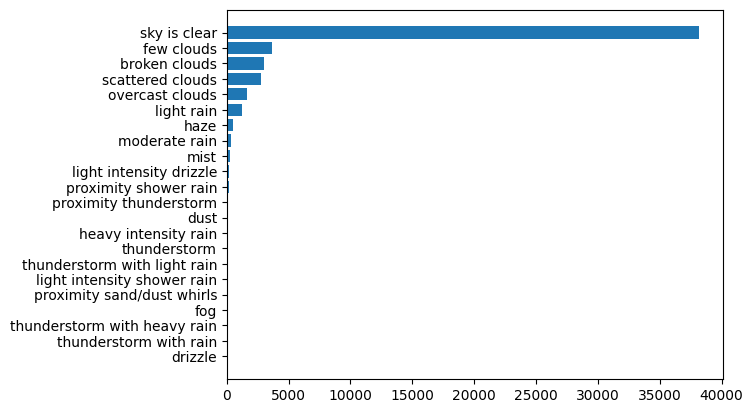

In [107]:
plt.barh("weather_descs", "count", data = crime_most_descs)
plt.show()

In [111]:
crimeWeather.to_csv("combined_weather_crime.csv", index = False)